#### Cartpole

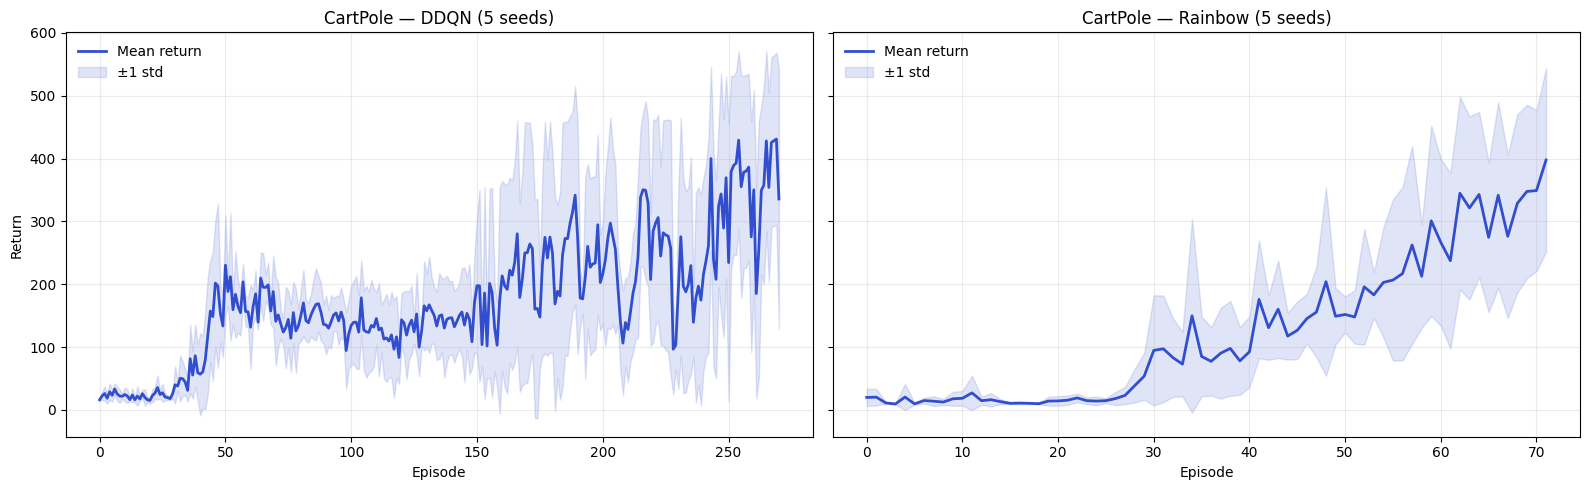

In [ ]:
import os
import torch
import numpy as np
import matplotlib.pyplot as plt

PROJECT_ROOT = "/Users/richardfisher/Desktop/projects/RainbowDQNAgent"
PROJECT_ROOT = r"C:\Users\richa\Desktop\RainbowDQNAgent"
os.chdir(PROJECT_ROOT)

DDQN_DIR = "models/CartPole/DDQN"
RAINBOW_DIR = "models/CartPole/Rainbow"
seed_files = ["one.pth", "two.pth", "three.pth", "four.pth", "five.pth"]

def load_runs(base_dir, files):
    runs = []
    for f in files:
        ckpt = torch.load(
            os.path.join(base_dir, f),
            map_location="cpu",
            weights_only=False
        )
        runs.append(np.array(ckpt["reward_history"]))
    return runs

ddqn_runs = load_runs(DDQN_DIR, seed_files)
rainbow_runs = load_runs(RAINBOW_DIR, seed_files)

min_len_ddqn = min(len(r) for r in ddqn_runs)
min_len_rainbow = min(len(r) for r in rainbow_runs)
ddqn_runs = np.array([r[:min_len_ddqn] for r in ddqn_runs])
rainbow_runs = np.array([r[:min_len_rainbow] for r in rainbow_runs])

ddqn_mean = ddqn_runs.mean(axis=0)
ddqn_std = ddqn_runs.std(axis=0)
ddqn_eps = np.arange(min_len_ddqn)

rainbow_mean = rainbow_runs.mean(axis=0)
rainbow_std = rainbow_runs.std(axis=0)
rainbow_eps = np.arange(min_len_rainbow)

COLOR = "#314ECF"

fig, axes = plt.subplots(1, 2, figsize=(16, 5), sharey=True)
axes[0].plot(ddqn_eps, ddqn_mean, color=COLOR, linewidth=2, label="Mean return", zorder=2)
axes[0].fill_between(ddqn_eps, ddqn_mean - ddqn_std, ddqn_mean + ddqn_std, color=COLOR, label="±1 std", alpha=0.15, zorder=1)
axes[0].set_title("CartPole — DDQN (5 seeds)")
axes[0].set_xlabel("Episode")
axes[0].set_ylabel("Return")
axes[0].grid(alpha=0.25)
axes[0].legend(frameon=False)
axes[1].plot(rainbow_eps, rainbow_mean, color=COLOR, linewidth=2, label="Mean return", zorder=2)
axes[1].fill_between(rainbow_eps, rainbow_mean - rainbow_std, rainbow_mean + rainbow_std, color=COLOR, label="±1 std", alpha=0.15, zorder=1)
axes[1].set_title("CartPole — Rainbow (5 seeds)")
axes[1].set_xlabel("Episode")
axes[1].grid(alpha=0.25)
axes[1].legend(frameon=False)

plt.tight_layout()
plt.show()
plt.show()


#### LunarLander

C:\Users\richa\AppData\Local\Temp\ipykernel_23864\2773539946.py:40: RuntimeWarning: invalid value encountered in divide
  return num / den


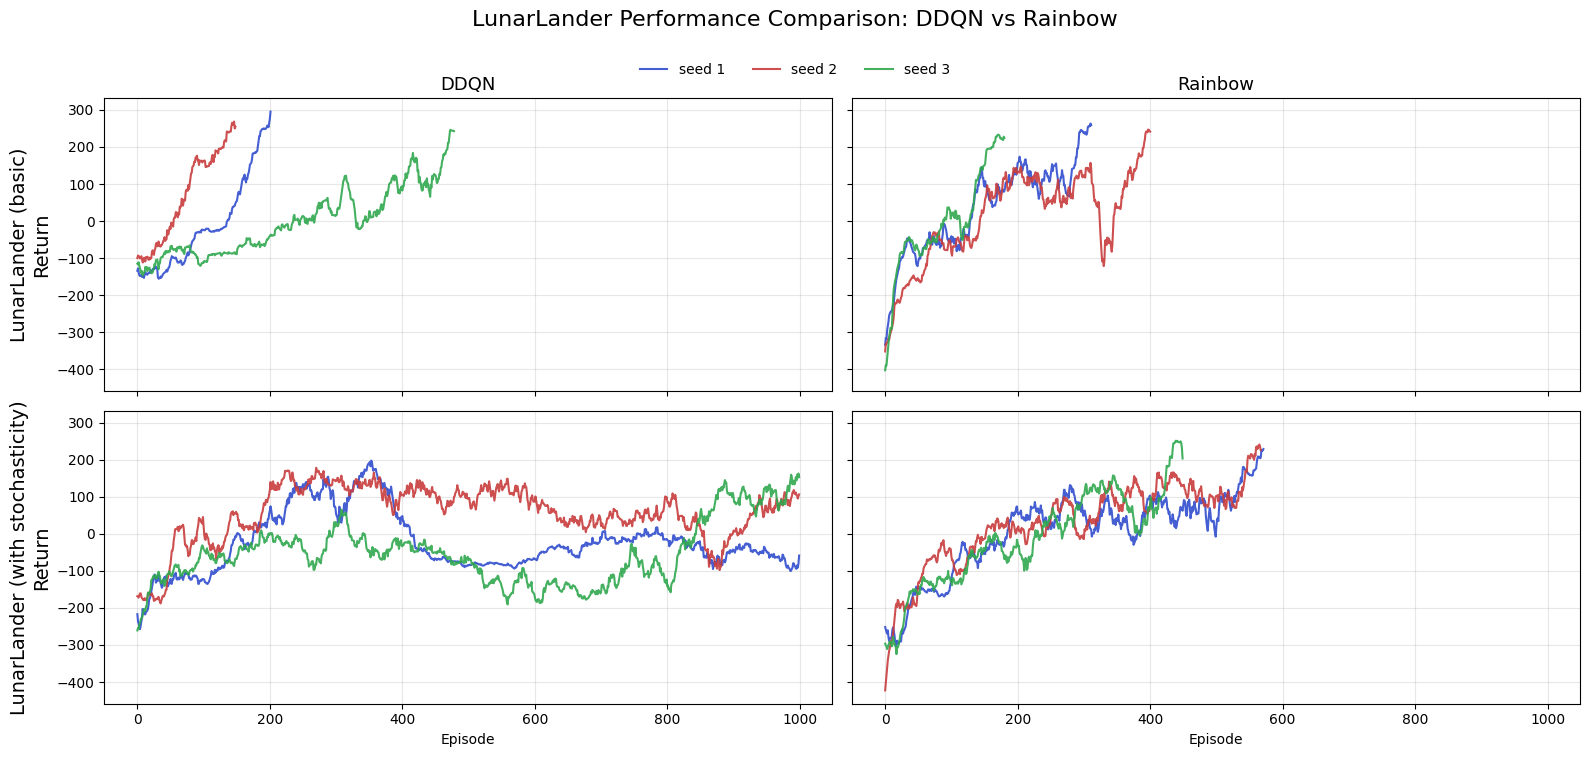

In [ ]:
import torch
import numpy as np
import matplotlib.pyplot as plt
import os

PROJECT_ROOT = "/Users/richardfisher/Desktop/projects/RainbowDQNAgent"
PROJECT_ROOT = r"C:\Users\richa\Desktop\RainbowDQNAgent"
os.chdir(PROJECT_ROOT)

CONFIGS = {
    "LunarLander (basic)": {
        "DDQN": [
            "models/Lunarlander_easy/DDQN/one.pth",
            "models/Lunarlander_easy/DDQN/two.pth",
            "models/Lunarlander_easy/DDQN/three.pth",
        ],
        "Rainbow": [
            "models/Lunarlander_easy/Rainbow/one.pth",
            "models/Lunarlander_easy/Rainbow/two.pth",
            "models/Lunarlander_easy/Rainbow/three.pth",
        ],
    },
    "LunarLander (with stochasticity)": {
        "DDQN": [
            "models/Lunarlander_hard/DDQN/one.pth",
            "models/Lunarlander_hard/DDQN/two.pth",
            "models/Lunarlander_hard/DDQN/three.pth",
        ],
        "Rainbow": [
            "models/Lunarlander_hard/Rainbow/one.pth",
            "models/Lunarlander_hard/Rainbow/two.pth",
            "models/Lunarlander_hard/Rainbow/three.pth",
        ],
    },
}

def moving_average_nan(x, window=20):
    num = np.convolve(np.nan_to_num(x), np.ones(window), mode="same")
    den = np.convolve(~np.isnan(x), np.ones(window), mode="same")
    return num / den

def load_padded_runs(files):
    runs = []
    max_len = 0

    for f in files:
        ckpt = torch.load(f, map_location="cpu", weights_only=False)
        r = np.array([float(d["return"]) for d in ckpt["reward_history"]])
        runs.append(r)
        max_len = max(max_len, len(r))
    padded = []
    
    for r in runs:
        p = np.full(max_len, np.nan)
        p[:len(r)] = r
        padded.append(p)

    return padded

SEED_COLORS = ["#314ECF", "#C83C3C", "#2FA84F"]  
LINEWIDTH = 1.5

fig, axes = plt.subplots(2, 2, figsize=(16, 8), sharex=True, sharey=True)
for row_idx, (env_name, algs) in enumerate(CONFIGS.items()):
    for col_idx, (alg_name, files) in enumerate(algs.items()):
        ax = axes[row_idx, col_idx]
        runs = load_padded_runs(files)
        for i, run in enumerate(runs):
            ax.plot(moving_average_nan(run, 20), label=f"seed {i+1}", color=SEED_COLORS[i], linewidth=LINEWIDTH,alpha=0.9)
        ax.grid(alpha=0.3)
        if row_idx == 0:
            ax.set_title(alg_name, fontsize=13)
        if col_idx == 0:
            ax.set_ylabel(f"{env_name}\nReturn", fontsize=14)
        if row_idx == 1:
            ax.set_xlabel("Episode")

handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper center", ncol=3, frameon=False, fontsize=10, bbox_to_anchor=(0.5, 0.89))
fig.suptitle("LunarLander Performance Comparison: DDQN vs Rainbow", fontsize=16, y=0.94)
plt.tight_layout(rect=[0, 0, 1, 0.92])
plt.show()

#### Pong

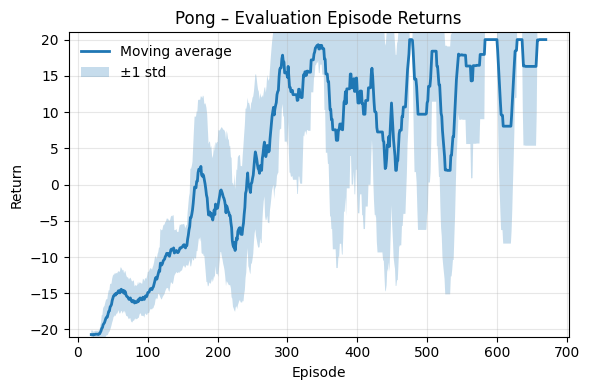

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

rewards = np.load(r"C:\Users\richa\Desktop\NEW\rewards_1765481250.npy")

WINDOW = 20  
mean_ma = np.convolve(rewards, np.ones(WINDOW) / WINDOW, mode="valid")
std_ma = np.array([rewards[i - WINDOW + 1 : i + 1].std() for i in range(WINDOW - 1, len(rewards))])
episodes = np.arange(WINDOW - 1, len(rewards))

plt.figure(figsize=(6, 4))
plt.plot(episodes, mean_ma, linewidth=2, label="Moving average")
plt.fill_between(episodes, mean_ma - std_ma, mean_ma + std_ma, alpha=0.25, label="±1 std")
plt.xlabel("Episode")
plt.ylabel("Return")
plt.title("Pong – Evaluation Episode Returns")
plt.ylim(-21, 21)
plt.grid(alpha=0.3)
plt.legend(frameon=False)
plt.tight_layout()
plt.show()


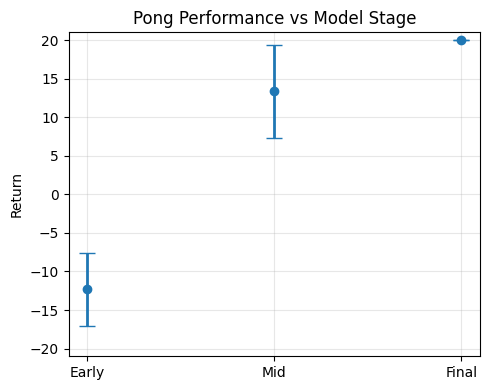

In [ ]:
early = np.array([-18.0, -19.0, -8.0, -11.0, -11.0, -18.0, -8.0, -8.0, -19.0, -19.0,
                  -8.0, -8.0, -8.0, -11.0, -8.0, -11.0, -19.0, -8.0, -8.0, -18.0])

mid = np.array([7.0, 7.0, 9.0, 20.0, 20.0, 7.0, 7.0, 7.0, 20.0, 7.0,
                20.0, 20.0, 20.0, 20.0, 20.0, 20.0, 9.0, 9.0, 9.0, 9.0])

final = np.array([20.0] * 20)

means = [early.mean(), mid.mean(), final.mean()]
stds  = [early.std(),  mid.std(),  final.std()]

labels = ["Early", "Mid", "Final"]

plt.figure(figsize=(5, 4))

plt.errorbar(labels, means, yerr=stds, fmt="o", capsize=6, linewidth=2)

plt.ylabel("Return")
plt.title("Pong Performance vs Model Stage")
plt.ylim(-21, 21)
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()


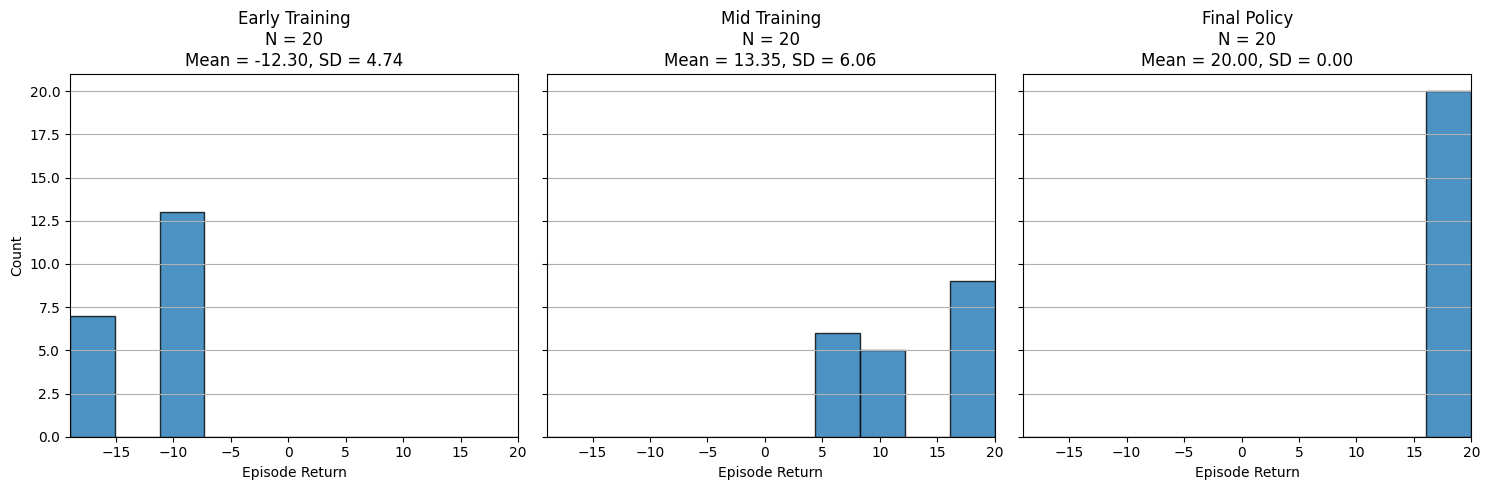

In [ ]:
# Data
early = np.array([
    -18.0, -19.0, -8.0, -11.0, -11.0, -18.0, -8.0, -8.0, -19.0, -19.0,
    -8.0, -8.0, -8.0, -11.0, -8.0, -11.0, -19.0, -8.0, -8.0, -18.0
])

mid = np.array([
    7.0, 7.0, 9.0, 20.0, 20.0, 7.0, 7.0, 7.0, 20.0, 7.0,
    20.0, 20.0, 20.0, 20.0, 20.0, 20.0, 9.0, 9.0, 9.0, 9.0
])

final = np.array([20.0] * 20)

stages = {"Early Training": early, "Mid Training": mid, "Final Policy": final}
bins = 10
all_returns = np.concatenate(list(stages.values()))
bin_edges = np.histogram(all_returns, bins=bins)[1]
fig, axes = plt.subplots(1, 3, figsize=(15, 5), sharey=True)
for ax, (name, returns) in zip(axes, stages.items()):
    mean = returns.mean()
    std = returns.std()
    n = len(returns)
    ax.hist(returns, bins=bin_edges, alpha=0.8, edgecolor="black")
    ax.set_xlim(bin_edges[0], bin_edges[-1])
    ax.set_title(f"{name}\n" f"N = {n}\n" f"Mean = {mean:.2f}, SD = {std:.2f}")
    ax.set_xlabel("Episode Return")
    ax.grid(True, axis="y")
axes[0].set_ylabel("Count")

plt.tight_layout()
plt.show()


#### Frosbite

In [ ]:
import sys
import os
import numpy as np
import matplotlib.pyplot as plt
import torch

In [ ]:
PROJECT_ROOT = r"C:\Users\richa\Desktop\RainbowDQNAgent\src"
sys.path.insert(0, PROJECT_ROOT)

from agents.rainbow import RainbowDQNAgent

PROJECT_ROOT = r"C:\Users\richa\Desktop\RainbowDQNAgent\models\Frostbite"
os.chdir(PROJECT_ROOT)

model_path = os.path.join(PROJECT_ROOT, "model_1034.pth")

config = {
    "batch_size": 32,
    "network": "cnn", 
    "gamma": 0.99,
    "memory_size": 1000,
    "n_step": 3, 
    "tau": 0.005,
    "lr": 5e-4,
    "num_episodes": 1000,
    "v_min": -300,
    "v_max": 300.0,            
    "atom_size": 51,      
    "env_name": "ALE/Frostbite-v5",     # LunarLander-v3     ALE/Pong-v5     CartPole-v1
}

agent = RainbowDQNAgent(config)
agent.load_model(model_path)

[LOAD] Model loaded from C:\Users\richa\Desktop\RainbowDQNAgent\models\Frostbite\model_1034.pth


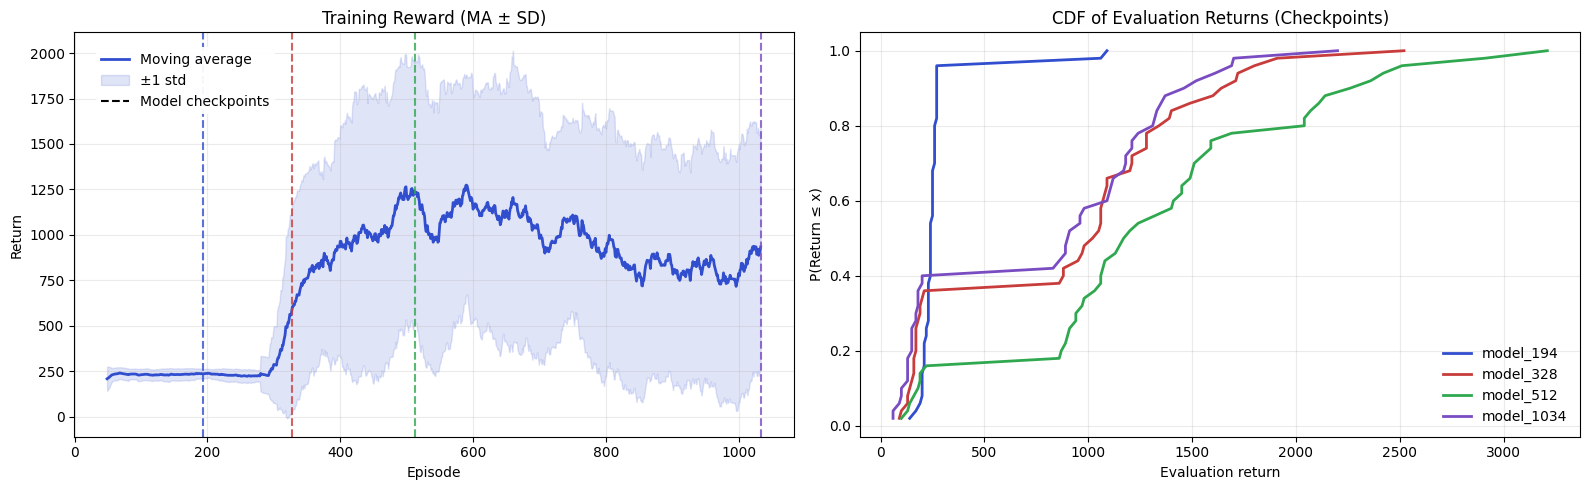

In [ ]:
BASE_COLOR = "#314ECF"
MODEL_COLORS = [
    "#314ECF",  
    "#C83C3C",  
    "#2FA84F",  
    "#7A4CC2",  
]
LINEWIDTH = 2

returns = np.asarray(agent.reward_history)
window = 50

ma = np.convolve(returns, np.ones(window) / window, mode="valid")
std = np.array([returns[i:i+window].std() for i in range(len(returns) - window + 1)])
x_ma = np.arange(window - 1, len(returns))

PROJECT_ROOT = r"C:\Users\richa\Desktop\RainbowDQNAgent\models\Frostbite"
os.chdir(PROJECT_ROOT)

model_names = ["model_194", "model_328", "model_512", "model_1034"]
checkpoint_episodes = [194, 328, 512, 1034]


fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 5))

ax1.plot(x_ma, ma, color=BASE_COLOR, linewidth=2, label="Moving average", zorder=2)
ax1.fill_between(x_ma, ma - std, ma + std, color=BASE_COLOR, alpha=0.15, label="±1 std",zorder=1)

for ep, color in zip(checkpoint_episodes, MODEL_COLORS):
    ax1.axvline(ep, color=color, linestyle="--", linewidth=1.5, alpha=0.8)

ax1.plot([], [], linestyle="--", color="black", linewidth=1.5, label="Model checkpoints")
ax1.set_xlabel("Episode")
ax1.set_ylabel("Return")
ax1.set_title("Training Reward (MA ± SD)")
ax1.grid(alpha=0.25)
ax1.legend(frameon=True, facecolor="white", framealpha=0.95, edgecolor="none", loc="upper left", bbox_to_anchor=(0.02, 0.98))

for model_name, color in zip(model_names, MODEL_COLORS):
    eval_returns = np.load(f"{model_name}_reward_eval.npy")
    x = np.sort(eval_returns)
    y = np.arange(1, len(x) + 1) / len(x)
    ax2.plot(x, y, color=color, linewidth=LINEWIDTH, label=model_name)

ax2.set_xlabel("Evaluation return")
ax2.set_ylabel("P(Return ≤ x)")
ax2.set_title("CDF of Evaluation Returns (Checkpoints)")
ax2.grid(alpha=0.25)
ax2.legend(frameon=False)

plt.tight_layout()
plt.show()


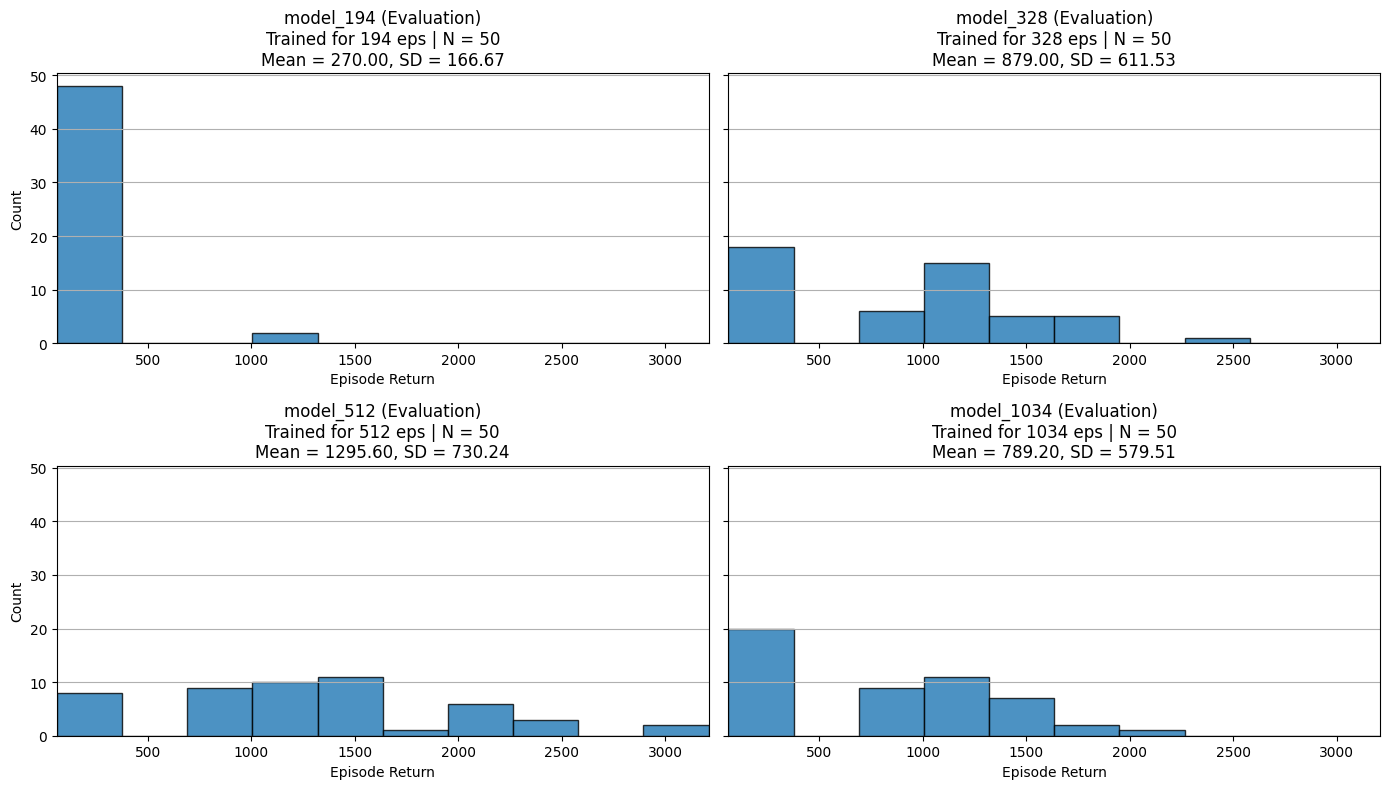

In [ ]:
PROJECT_ROOT = r"C:\Users\richa\Desktop\RainbowDQNAgent\models\Frostbite"
os.chdir(PROJECT_ROOT)

model_names = ["model_194", "model_328", "model_512", "model_1034"]
bins = 10

all_returns = np.concatenate([np.load(f"{m}_reward_eval.npy") for m in model_names])
bin_edges = np.histogram(all_returns, bins=bins)[1]

fig, axes = plt.subplots(2, 2, figsize=(14, 8), sharey=True)
axes = axes.flatten()
for ax, model_name in zip(axes, model_names):
    eval_path = f"{model_name}_reward_eval.npy"
    checkpoint_path = f"{model_name}.pth"

    # Load evaluation data
    episode_returns = np.load(eval_path)
    n_samples = len(episode_returns)

    # Load checkpoint for training length
    checkpoint = torch.load(checkpoint_path, map_location="cpu")
    trained_episodes = len(checkpoint["reward_history"])

    # Stats
    mean = episode_returns.mean()
    std = episode_returns.std()

    # Histogram
    ax.hist(episode_returns, bins=bin_edges, alpha=0.8, edgecolor="black")
    ax.set_xlim(bin_edges[0], bin_edges[-1])
    ax.set_title(f"{model_name} (Evaluation)\n" f"Trained for {trained_episodes} eps | N = {n_samples}\n" f"Mean = {mean:.2f}, SD = {std:.2f}")
    ax.set_xlabel("Episode Return")
    ax.grid(True, axis="y")

axes[0].set_ylabel("Count")
axes[2].set_ylabel("Count")

plt.tight_layout()
plt.show()


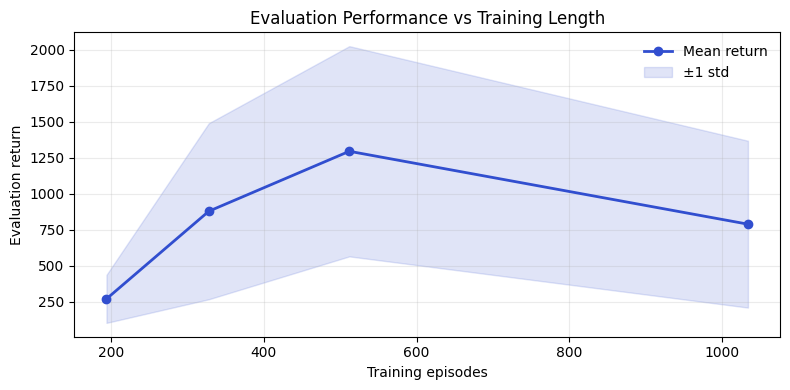

In [ ]:
PROJECT_ROOT = r"C:\Users\richa\Desktop\RainbowDQNAgent\models\Frostbite"
os.chdir(PROJECT_ROOT)

model_names = ["model_194", "model_328", "model_512", "model_1034"]

BASE_COLOR = "#314ECF"

means = []
stds = []
training_lengths = []
for model_name in model_names:
    episode_returns = np.load(f"{model_name}_reward_eval.npy")
    checkpoint = torch.load(f"{model_name}.pth", map_location="cpu")
    means.append(episode_returns.mean())
    stds.append(episode_returns.std())
    training_lengths.append(len(checkpoint["reward_history"]))

means = np.array(means)
stds = np.array(stds)
training_lengths = np.array(training_lengths)

plt.figure(figsize=(8, 4))
plt.plot(training_lengths, means, color=BASE_COLOR, linewidth=2, marker="o", label="Mean return", zorder=2)
plt.fill_between(training_lengths, means - stds, means + stds, color=BASE_COLOR, alpha=0.15, label="±1 std", zorder=1)
plt.xlabel("Training episodes")
plt.ylabel("Evaluation return")
plt.title("Evaluation Performance vs Training Length")
plt.grid(alpha=0.25)
plt.legend(frameon=False)
plt.tight_layout()
plt.show()


#### Heatmap

In [ ]:
import sys
import os
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import matplotlib as mpl
from agents.rainbow import RainbowDQNAgent
import torch
import torch.nn.functional as F

In [ ]:
def grad_cam_for_state(agent, state):

    agent.policy_net.eval()
    state_t = torch.tensor(state, dtype=torch.float32, device=agent.device).unsqueeze(0)
    state_t.requires_grad_(True)

    # forward with feature access
    dist, features = agent.policy_net(state_t, return_features=True)
    features.retain_grad()
    q_vals = agent.c51.expectation(dist)
    action = q_vals.argmax(dim=1)
    q_sa = q_vals[0, action]
    agent.policy_net.zero_grad()
    q_sa.backward()

    # Grad-CAM
    weights = features.grad.mean(dim=(2, 3), keepdim=True)
    cam = (weights * features).sum(dim=1)
    cam = F.relu(cam)

    # Normalize
    cam -= cam.min()
    cam /= cam.max() + 1e-8
    cam = F.interpolate(cam.unsqueeze(1), size=(84, 84), mode="bilinear", align_corners=False).squeeze()

    return cam.detach().cpu(), action.item()

In [21]:
PROJECT_ROOT = r"C:\Users\richa\Desktop\RainbowDQNAgent\src"
sys.path.insert(0, PROJECT_ROOT)

PROJECT_ROOT = r"C:\Users\richa\Desktop\RainbowDQNAgent\models\Frostbite"
os.chdir(PROJECT_ROOT)

model_path = os.path.join(PROJECT_ROOT, "model_1034.pth")

config = {
    "batch_size": 32,
    "network": "cnn", 
    "gamma": 0.99,
    "memory_size": 1000,
    "n_step": 3, 
    "tau": 0.005,
    "lr": 5e-4,
    "num_episodes": 1000,
    "v_min": -300,
    "v_max": 300.0,            
    "atom_size": 51,      
    "env_name": "ALE/Frostbite-v5",     # LunarLander-v3     ALE/Pong-v5     CartPole-v1
}

agent = RainbowDQNAgent(config)
agent.load_model(model_path)

[LOAD] Model loaded from C:\Users\richa\Desktop\RainbowDQNAgent\models\Frostbite\model_1034.pth


In [22]:
states = []
state, _ = agent.env.reset(seed=2)
for _ in range(100):   # make sure t=30 exists
    states.append(state)
    state_t = torch.tensor(state, dtype=torch.float32, device=agent.device).unsqueeze(0)
    with torch.no_grad():
        dist = agent.policy_net(state_t)
        q_vals = agent.c51.expectation(dist)
        action = q_vals.argmax(dim=1).item()
    state, _, done, truncated, _ = agent.env.step(action)
    if done or truncated:
        break

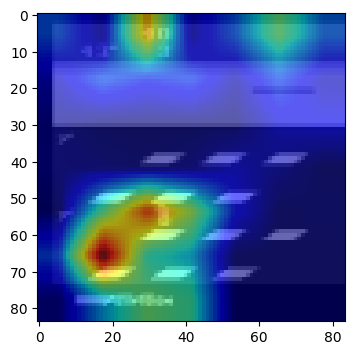

In [ ]:
t = 51
cam, action = grad_cam_for_state(agent, states[t])
plt.figure(figsize=(4.5, 4))
plt.imshow(states[t][0], cmap="gray")
plt.imshow(cam, cmap="jet", alpha=0.6)

In [ ]:
PROJECT_ROOT = r"C:\Users\richa\Desktop\RainbowDQNAgent\src"
sys.path.insert(0, PROJECT_ROOT)


PROJECT_ROOT = r"C:\Users\richa\Desktop\RainbowDQNAgent\models\Frostbite"
os.chdir(PROJECT_ROOT)

model_path = os.path.join(PROJECT_ROOT, "model_194.pth")

config = {
    "batch_size": 32,
    "network": "cnn", 
    "gamma": 0.99,
    "memory_size": 1000,
    "n_step": 3, 
    "tau": 0.005,
    "lr": 5e-4,
    "num_episodes": 1000,
    "v_min": -300,
    "v_max": 300.0,            
    "atom_size": 51,      
    "env_name": "ALE/Frostbite-v5",     # LunarLander-v3     ALE/Pong-v5     CartPole-v1
}

agent = RainbowDQNAgent(config)
agent.load_model(model_path)

[LOAD] Model loaded from C:\Users\richa\Desktop\RainbowDQNAgent\models\Frostbite\model_194.pth


In [27]:
states = []
state, _ = agent.env.reset(seed=0)
for _ in range(1000):   # make sure t=30 exists
    states.append(state)
    state_t = torch.tensor(state, dtype=torch.float32, device=agent.device).unsqueeze(0)
    with torch.no_grad():
        dist = agent.policy_net(state_t)
        q_vals = agent.c51.expectation(dist)
        action = q_vals.argmax(dim=1).item()
    state, _, done, truncated, _ = agent.env.step(action)
    if done or truncated:
        break

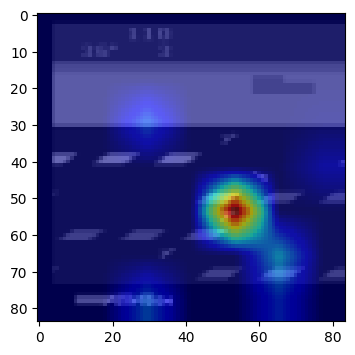

In [ ]:
t = 200
cam, action = grad_cam_for_state(agent, states[t])
plt.figure(figsize=(4.5, 4))
plt.imshow(states[t][0], cmap="gray")
plt.imshow(cam, cmap="jet", alpha=0.6)

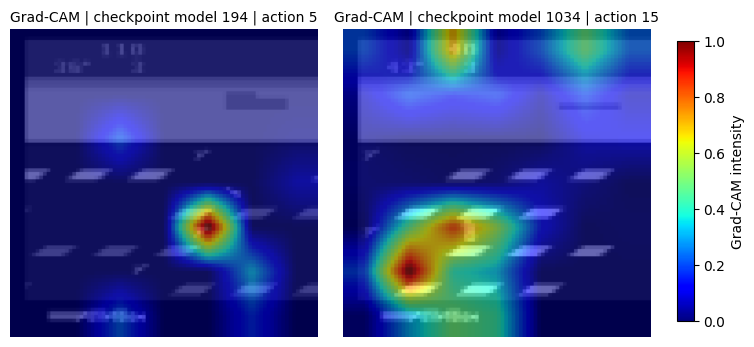

In [ ]:
img1 = mpimg.imread("gradcam_t200.png")
img2 = mpimg.imread("gradcam_t51.png")
fig, axs = plt.subplots(1, 2, figsize=(8.5, 4))
axs[0].imshow(img1)
axs[0].axis("off")
axs[0].set_title("Grad-CAM | checkpoint model 194 | action 5", fontsize=10)
axs[1].imshow(img2)
axs[1].axis("off")
axs[1].set_title("Grad-CAM | checkpoint model 1034 | action 15", fontsize=10)
norm = mpl.colors.Normalize(vmin=0, vmax=1)
sm = mpl.cm.ScalarMappable(norm=norm, cmap="jet")
sm.set_array([])
cax = fig.add_axes([0.92, 0.15, 0.02, 0.7])
cbar = fig.colorbar(sm, cax=cax)
cbar.set_label("Grad-CAM intensity", fontsize=10)
plt.subplots_adjust(wspace=0.02)
plt.show()
